Screen time analysis using python

STEP 1: DATASET INFORMATION
Dataset Shape: (2000, 20)

First 5 Records:
  Person_ID  Age Gender    City        State  Occupation Primary_Language  \
0   INP0001   18   Male  Nagpur  Maharashtra  Freelancer          English   
1   INP0001   18   Male  Nagpur  Maharashtra  Freelancer          English   
2   INP0001   18   Male  Nagpur  Maharashtra  Freelancer          English   
3   INP0001   18   Male  Nagpur  Maharashtra  Freelancer          English   
4   INP0001   18   Male  Nagpur  Maharashtra  Freelancer          English   

  Phone_OS Internet_Type        Date        App  Usage  Notifications  \
0  Android  Wi-Fi mostly  09/01/2026   WhatsApp      1             30   
1  Android  Wi-Fi mostly  09/01/2026  Instagram     12             23   
2  Android  Wi-Fi mostly  09/01/2026    YouTube      0             11   
3  Android  Wi-Fi mostly  09/01/2026     Chrome      7             21   
4  Android  Wi-Fi mostly  09/01/2026   Facebook     23             12   

   Times opened  Data_Usag

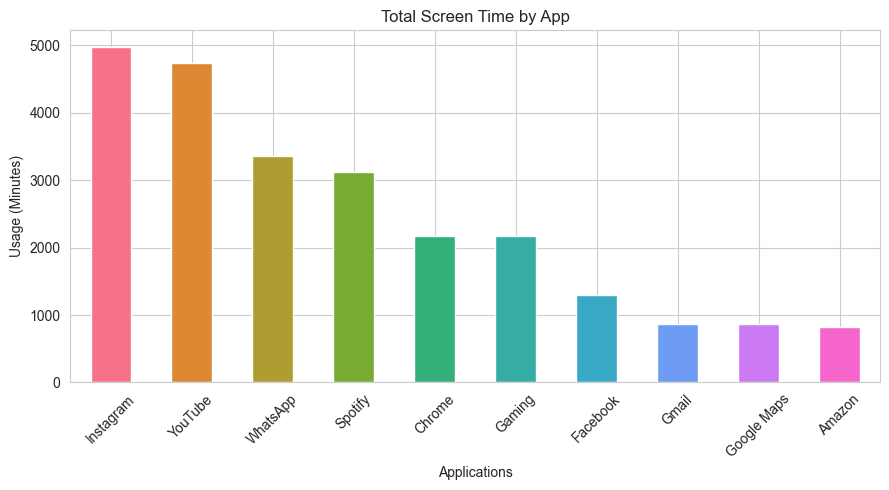

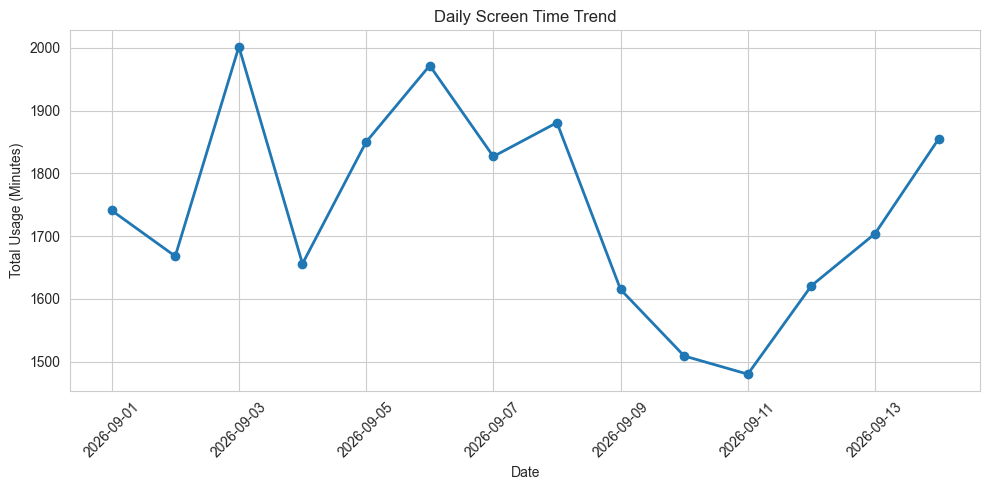

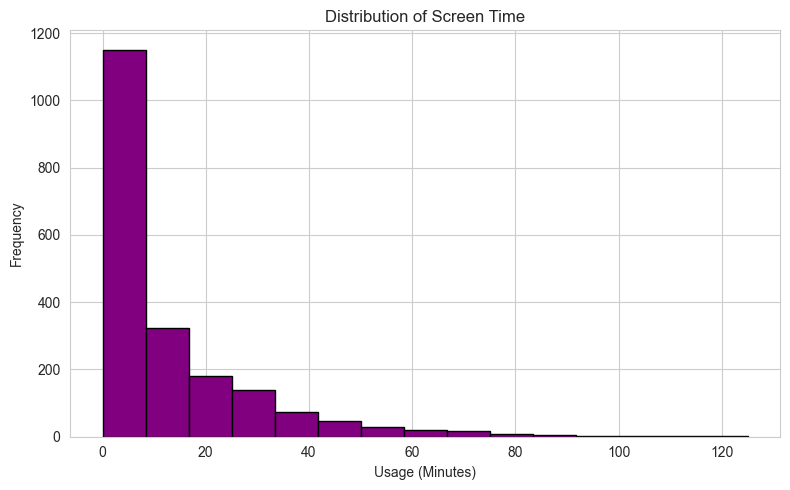

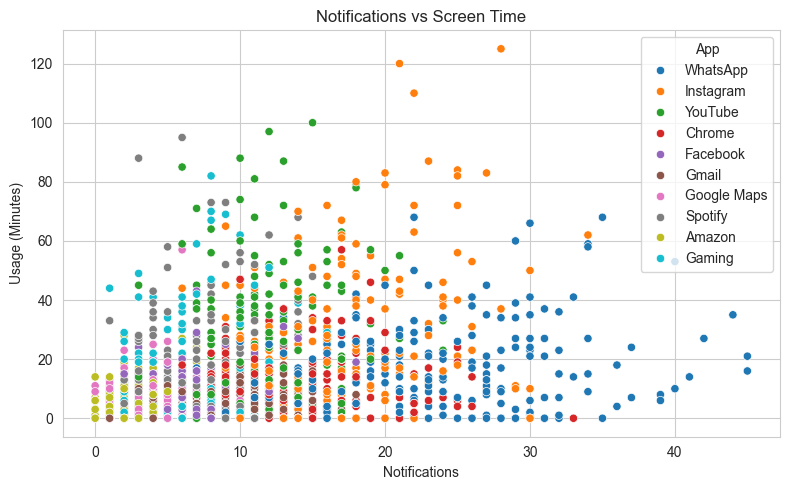

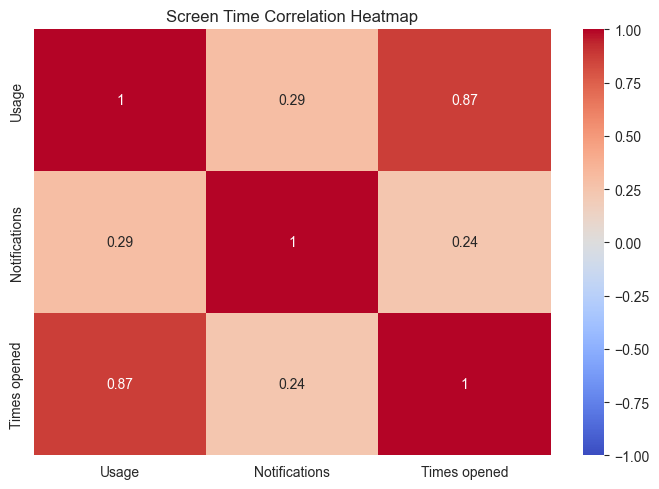


All 5 Graphs Generated Successfully!
Cleaned Dataset Saved Successfully!

Analysis Completed!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create folder to save graphs
os.makedirs("graphs", exist_ok=True)

sns.set_style("whitegrid")

# ---------------------------------------------------------------
# 1. LOAD THE DATASET
# ---------------------------------------------------------------

df = pd.read_csv("india_screen_time_dataset.csv")

print("=" * 50)
print("STEP 1: DATASET INFORMATION")
print("=" * 50)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


# ---------------------------------------------------------------
# 2. DATA CLEANING
# ---------------------------------------------------------------

print("\n" + "=" * 50)
print("STEP 2: DATA CLEANING")
print("=" * 50)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Remove duplicate records
print("\nDuplicate Records:", df.duplicated().sum())
df = df.drop_duplicates()

# Remove extra spaces from app names
df["App"] = df["App"].str.strip()

# Convert date into datetime format
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")

# Convert numerical columns
columns = ["Usage", "Notifications", "Times opened"]

for col in columns:
    df[col] = pd.to_numeric(df[col])

print("\nCleaning Completed!")
print("Final Dataset Shape:", df.shape)

# Save cleaned dataset
df.to_csv("india_screen_time_cleaned.csv", index=False)


# ---------------------------------------------------------------
# 3. DATA ANALYSIS
# ---------------------------------------------------------------

print("\n" + "=" * 50)
print("STEP 3: DATA ANALYSIS")
print("=" * 50)

# Basic statistical analysis
print("\nScreen Time Statistics:")
print("Average Usage:", df["Usage"].mean())
print("Maximum Usage:", df["Usage"].max())
print("Minimum Usage:", df["Usage"].min())
print("Total Usage:", df["Usage"].sum())

print("\nNotification Statistics:")
print("Average Notifications:", df["Notifications"].mean())
print("Total Notifications:", df["Notifications"].sum())

print("\nApp Opening Statistics:")
print("Average Times Opened:", df["Times opened"].mean())
print("Total App Openings:", df["Times opened"].sum())

# App-wise analysis
print("\nApp-wise Screen Time:")
app_usage = df.groupby("App")["Usage"].sum().sort_values(ascending=False)
print(app_usage)

# Age-wise analysis
print("\nAge-wise Screen Time:")
age_usage = df.groupby("Age")["Usage"].mean()
print(age_usage.round(2))

# City-wise analysis
print("\nCity-wise Screen Time:")
city_usage = df.groupby("City")["Usage"].mean().sort_values(ascending=False)
print(city_usage.round(2))

# Correlation analysis
print("\nCorrelation Between Usage, Notifications and App Openings:")

correlation = df[["Usage", "Notifications", "Times opened"]].corr()
print(correlation.round(2))


# ---------------------------------------------------------------
# 4. DATA VISUALIZATION
# ---------------------------------------------------------------

print("\n" + "=" * 50)
print("STEP 4: DATA VISUALIZATION")
print("=" * 50)


# GRAPH 1: APP-WISE SCREEN TIME BAR CHART

plt.figure(figsize=(9, 5))

app_usage.plot(
    kind="bar",
    color=sns.color_palette("husl", len(app_usage))
)

plt.title("Total Screen Time by App")
plt.xlabel("Applications")
plt.ylabel("Usage (Minutes)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("graphs/graph1_app_usage.png")
plt.show()
plt.close()


# GRAPH 2: DAILY SCREEN TIME LINE GRAPH

daily_usage = df.groupby("Date")["Usage"].sum()

plt.figure(figsize=(10, 5))

plt.plot(
    daily_usage.index,
    daily_usage.values,
    marker="o",
    linewidth=2
)

plt.title("Daily Screen Time Trend")
plt.xlabel("Date")
plt.ylabel("Total Usage (Minutes)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("graphs/graph2_daily_usage.png")
plt.show()
plt.close()


# GRAPH 3: SCREEN TIME DISTRIBUTION HISTOGRAM

plt.figure(figsize=(8, 5))

plt.hist(
    df["Usage"],
    bins=15,
    color="purple",
    edgecolor="black"
)

plt.title("Distribution of Screen Time")
plt.xlabel("Usage (Minutes)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("graphs/graph3_usage_distribution.png")
plt.show()
plt.close()


# GRAPH 4: NOTIFICATIONS VS SCREEN TIME SCATTER PLOT

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Notifications",
    y="Usage",
    hue="App"
)

plt.title("Notifications vs Screen Time")
plt.xlabel("Notifications")
plt.ylabel("Usage (Minutes)")
plt.tight_layout()

plt.savefig("graphs/graph4_notifications_usage.png")
plt.show()
plt.close()


# GRAPH 5: CORRELATION HEATMAP

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Screen Time Correlation Heatmap")
plt.tight_layout()

plt.savefig("graphs/graph5_correlation.png")
plt.show()
plt.close()


print("\nAll 5 Graphs Generated Successfully!")
print("Cleaned Dataset Saved Successfully!")
print("\nAnalysis Completed!")